# Lab 3: PCA from Scratch for Image Compression

MLPR, Semester 4. Principal Component Analysis implemented with NumPy only (no `sklearn.decomposition.PCA`, as the lab requires). It is applied to a satellite image of the Plaksha campus, which is then reconstructed from different numbers of components.

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

image = cv2.imread("data/sat_image_plaksha.jpg")
gray_image = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY).astype(np.float64)

# Each image row is a sample and each column a feature
mean_column = np.mean(gray_image, axis=0)
image_mean_subtracted = gray_image - mean_column

cov_matrix = np.cov(image_mean_subtracted, rowvar=False)
eigenvalues, eigenvectors = np.linalg.eigh(cov_matrix)       # symmetric matrix -> real eigenpairs
order = np.argsort(eigenvalues)[::-1]
eigenvalues, eigenvectors = eigenvalues[order], eigenvectors[:, order]
explained = np.cumsum(eigenvalues) / eigenvalues.sum()
print("image shape:", gray_image.shape)

image shape: (264, 300)


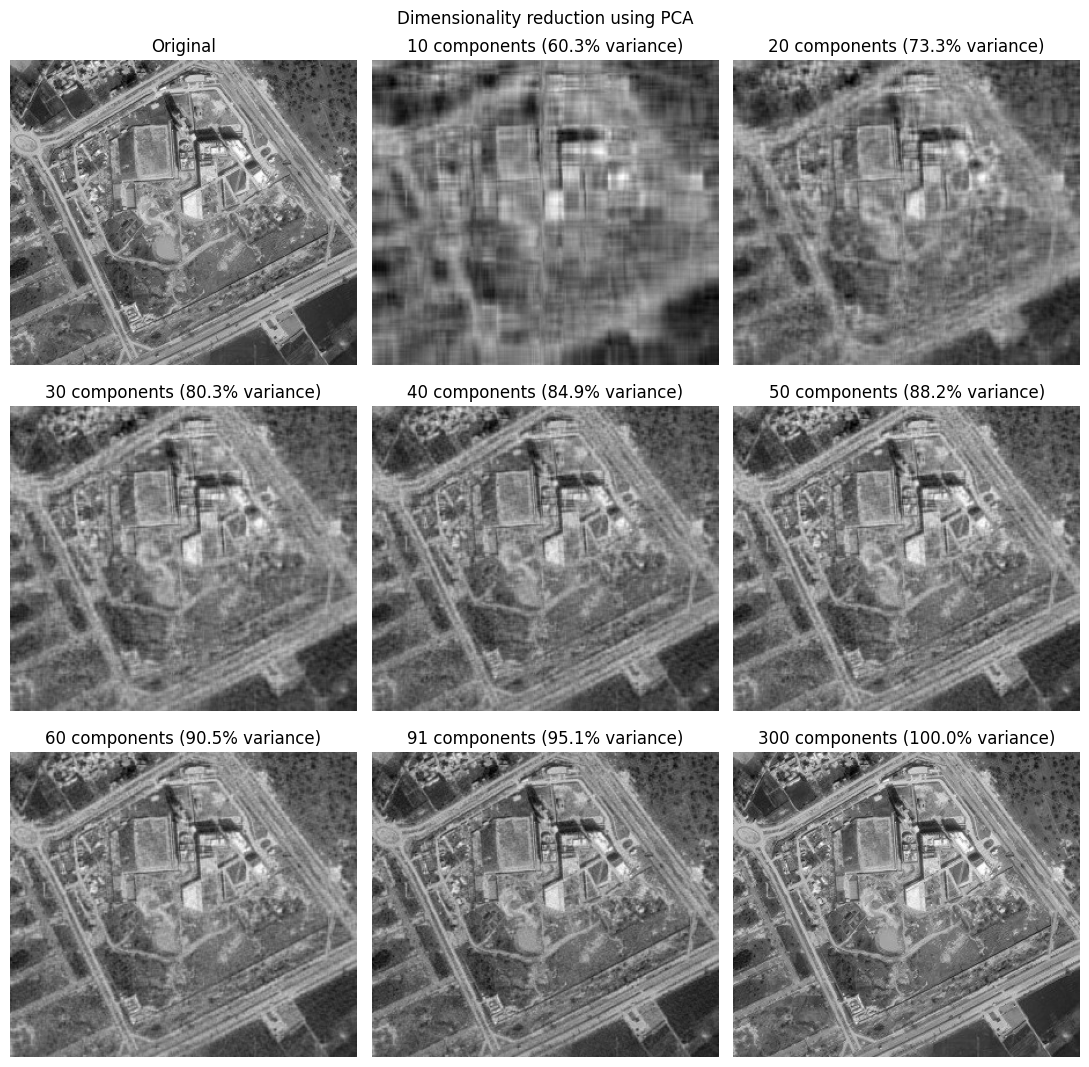

In [2]:
num_components_list = [10, 20, 30, 40, 50, 60, 91, 300]
fig, axes = plt.subplots(3, 3, figsize=(11, 11))
axes[0, 0].imshow(gray_image, cmap="gray"); axes[0, 0].set_title("Original")
for ax, k in zip(axes.flat[1:], num_components_list):
    W = eigenvectors[:, :k]
    reconstructed = (image_mean_subtracted @ W) @ W.T + mean_column
    ax.imshow(reconstructed, cmap="gray")
    ax.set_title(f"{k} components ({explained[k - 1] * 100:.1f}% variance)")
for ax in axes.flat: ax.axis("off")
plt.suptitle("Dimensionality reduction using PCA")
plt.tight_layout()
plt.savefig("images/lab03_pca.png")
plt.show()

Explained variance with 91 components: 95.06%
Components needed for 95% of the variance: 91 of 300


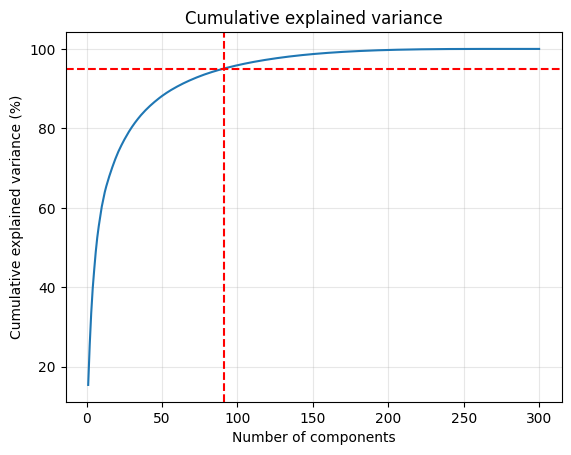

In [3]:
k95 = int(np.argmax(explained >= 0.95)) + 1
print(f"Explained variance with 91 components: {explained[90] * 100:.2f}%")
print(f"Components needed for 95% of the variance: {k95} of {len(eigenvalues)}")
plt.plot(np.arange(1, len(explained) + 1), explained * 100)
plt.axhline(95, color="r", ls="--"); plt.axvline(k95, color="r", ls="--")
plt.xlabel("Number of components"); plt.ylabel("Cumulative explained variance (%)")
plt.grid(alpha=0.3); plt.title("Cumulative explained variance")
plt.show()

## Report

1. PCA creates new features (linear combinations of the old ones) that capture the most variance. Feature selection only keeps a subset of the original features, unchanged.
2. Standardisation makes every feature contribute fairly to the variance, so features with large units do not dominate the components.
3. The covariance matrix captures how features vary together. Its eigenvectors give the directions of maximum variance.
4. PCA assumes linear relationships, is sensitive to outliers, and its components are harder to interpret than the original features.
5. The explained-variance ratio shows how much information each principal component keeps. Here about 91 components keep 95% of the image's variance.